# NYC Yellow Taxi — Trip Duration Model (January 2025)

## 1. Imports

In [13]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import optuna
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, root_mean_squared_log_error

sys.path.append("..")   # so the notebook can find src/
from src.experiment import train_and_log, log_model_run
from src.features import build_features, build_zone_xy
from src.train import split_by_time

## 2. Load data

In [2]:
url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-01.parquet"
df = pd.read_parquet(url)

cols = ["tpep_pickup_datetime", "tpep_dropoff_datetime",
        "PULocationID", "DOLocationID"]
df = df[cols].copy()
df.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID
0,2025-01-01 00:18:38,2025-01-01 00:26:59,229,237
1,2025-01-01 00:32:40,2025-01-01 00:35:13,236,237
2,2025-01-01 00:44:04,2025-01-01 00:46:01,141,141
3,2025-01-01 00:14:27,2025-01-01 00:20:01,244,244
4,2025-01-01 00:21:34,2025-01-01 00:25:06,244,116


## 3. Filter & sort

In [3]:
# Keep only January pickups (some rows have wrong dates), then sort by time
df = df[(df["tpep_pickup_datetime"] >= "2025-01-01") & (df["tpep_pickup_datetime"] < "2025-02-01")]
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

## 4. `prepare()`: target and time features

In [4]:
def prepare(df):
    df = df[["tpep_pickup_datetime", "tpep_dropoff_datetime",
             "PULocationID", "DOLocationID"]].copy()

    df["duration"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    df["hour"] = df["tpep_pickup_datetime"].dt.hour
    df["day_of_week"] = df["tpep_pickup_datetime"].dt.day_of_week
    df["PU_DO"] = df["PULocationID"].astype(str) + "_" + df["DOLocationID"].astype(str)

    df = df.drop(columns=["tpep_pickup_datetime", "tpep_dropoff_datetime"])
    return df

## 5. Clean & sample split (train Jan 1-20 / val Jan 21-25)

In [ ]:
# Prepare and clean all of January (df is sorted by pickup time)
d = prepare(df)
d = d[(d["duration"] >= 1) & (d["duration"] <= 60)]

# Random 500,000 trips, put back in time order
d = d.sample(n=500_000, random_state=42).sort_index()

# Split by date: train Jan 1-20, validation Jan 21-25.
# The test period (Jan 26-31) is only used once, for the final all-data model.
sample = df.loc[d.index]
tr_s, va_s, _ = split_by_time(sample)
y_train, y_val = d.loc[tr_s, "duration"], d.loc[va_s, "duration"]
print(f"Train: {len(y_train):,}  Val: {len(y_val):,}")

## 6. Features (shared `src.features` code, same as the API)

In [7]:
# Zone centers (data/taxi_zones/ is downloaded on first use) and the model features
zone_xy = build_zone_xy(Path("../data"))
X_sample = build_features(sample, zone_xy)
X_train, X_val = X_sample[tr_s], X_sample[va_s]

## 7. Feature list

In [8]:
features4 = ["PULocationID", "DOLocationID", "hour", "day_of_week",
             "is_holiday", "PU_lat", "PU_lon", "DO_lat", "DO_lon", "straight_dist"]
print(features4)

['PULocationID', 'DOLocationID', 'hour', 'day_of_week', 'is_holiday', 'PU_lat', 'PU_lon', 'DO_lat', 'DO_lon', 'straight_dist']


## 8. Baseline model

In [9]:
baseline, _ = train_and_log(
    {"n_estimators": 50, "max_depth": 20, "min_samples_leaf": 5},
    X_train[features4], y_train, X_val[features4], y_val,
    run_name="rf-baseline", tracking_dir="../mlruns",
    register_name="nyc-taxi-duration-rf")

2026/11/18 10:12:11 INFO mlflow.tracking.fluent: Experiment with name 'nyc-taxi-duration' does not exist. Creating a new experiment.
2026/11/18 10:12:20 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


rf-baseline {'val_rmse': 4.5221, 'val_rmsle': 0.3137}
Registered nyc-taxi-duration-rf version 1 (no alias set - set 'champion' in the MLflow UI if you want to serve it)


Successfully registered model 'nyc-taxi-duration-rf'.
Created version '1' of model 'nyc-taxi-duration-rf'.


## 9. Optuna tuning

In [14]:
mlflow.set_tracking_uri(Path("../mlruns").resolve().as_uri())
mlflow.set_experiment("nyc-taxi-duration")

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 200, step=50),
        "max_depth": trial.suggest_int("max_depth", 10, 40),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_categorical("max_features", [1.0, 0.7, 0.5]),
    }
    with mlflow.start_run(run_name=f"trial-{trial.number}", nested=True):
        m = RandomForestRegressor(**params, n_jobs=-1, random_state=42)
        m.fit(X_train[features4], y_train)
        rmse = root_mean_squared_error(y_val, m.predict(X_val[features4]))
        mlflow.log_params(params)
        mlflow.log_metric("val_rmse", rmse)
    return rmse

with mlflow.start_run(run_name="optuna-tuning"):
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=20)
    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_metric("best_val_rmse", study.best_value)

print(f"Best RMSE: {study.best_value:.3f}")
print("Best params:", study.best_params)

[I 2026-11-18 10:18:23,570] A new study created in memory with name: no-name-24100a48-9812-44ea-95ac-2fc4a6eb7a1d
[I 2026-11-18 10:18:38,181] Trial 0 finished with value: 4.525675844480211 and parameters: {'n_estimators': 100, 'max_depth': 39, 'min_samples_leaf': 15, 'max_features': 1.0}. Best is trial 0 with value: 4.525675844480211.
[I 2026-11-18 10:18:42,998] Trial 1 finished with value: 4.5062392229723685 and parameters: {'n_estimators': 50, 'max_depth': 36, 'min_samples_leaf': 13, 'max_features': 0.5}. Best is trial 1 with value: 4.5062392229723685.
[I 2026-11-18 10:19:01,309] Trial 2 finished with value: 4.562896517391701 and parameters: {'n_estimators': 200, 'max_depth': 16, 'min_samples_leaf': 4, 'max_features': 0.5}. Best is trial 1 with value: 4.5062392229723685.
[I 2026-11-18 10:19:10,499] Trial 3 finished with value: 4.528940461527352 and parameters: {'n_estimators': 100, 'max_depth': 19, 'min_samples_leaf': 13, 'max_features': 0.5}. Best is trial 1 with value: 4.5062392229

Best RMSE: 4.485
Best params: {'n_estimators': 200, 'max_depth': 25, 'min_samples_leaf': 8, 'max_features': 0.5}


## 10. Final model on all data

In [16]:
# All January trips of 1-60 minutes
full = df.copy()
full["duration"] = (full["tpep_dropoff_datetime"] - full["tpep_pickup_datetime"]).dt.total_seconds() / 60
full = full[full["duration"].between(1, 60)]

X_full = build_features(full, zone_xy)
y_full = full["duration"]
tr, va, te = split_by_time(full)
print(f"Train: {tr.sum():,}  Val: {va.sum():,}  Test: {te.sum():,}")

Train: 2,084,859  Val: 637,543  Test: 680,825


In [17]:
start = time.time()
big = RandomForestRegressor(**study.best_params, n_jobs=-1, random_state=42)
big.fit(X_full.loc[tr, features4], y_full[tr])
print(f"Training took {time.time() - start:.0f} s")

val_pred = big.predict(X_full.loc[va, features4])
val_rmse = root_mean_squared_error(y_full[va], val_pred)
val_rmsle = root_mean_squared_log_error(y_full[va], val_pred)
print(f"Val RMSE (all Jan 21-25 trips): {val_rmse:.3f}  RMSLE: {val_rmsle:.4f}")

Training took 261 s
Val RMSE (all Jan 21-25 trips): 4.344


In [18]:
test_pred = big.predict(X_full.loc[te, features4])
metrics = {
    "val_rmse": val_rmse,
    "val_rmsle": val_rmsle,
    "test_rmse": root_mean_squared_error(y_full[te], test_pred),
    "test_rmsle": root_mean_squared_log_error(y_full[te], test_pred),
}

log_model_run(
    big, study.best_params, metrics, features4,
    run_name="rf-final-all-data", tracking_dir="../mlruns",
    register_name="nyc-taxi-duration-rf")

2026/11/18 10:30:00 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'nyc-taxi-duration-rf' already exists. Creating a new version of this model...
Created version '2' of model 'nyc-taxi-duration-rf'.


rf-final-all-data {'val_rmse': 4.3441, 'test_rmse': 4.3516, 'test_rmsle': 0.3051}
Registered nyc-taxi-duration-rf version 2 (no alias set - set 'champion' in the MLflow UI if you want to serve it)


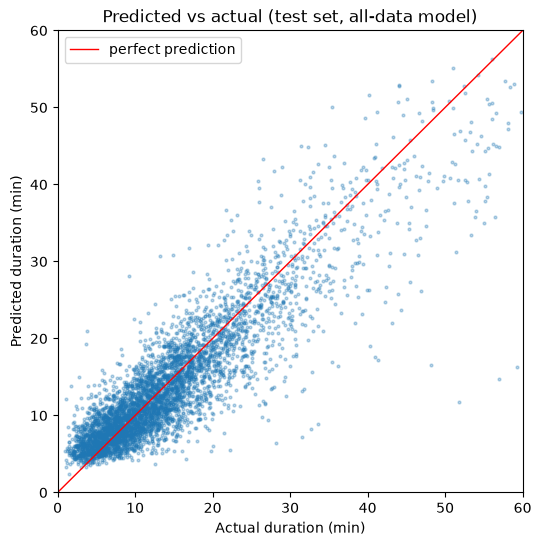

In [20]:
comparison_full = pd.DataFrame({"actual": y_full[te].values, "predicted": test_pred})
s = comparison_full.sample(5000, random_state=42)

plt.figure(figsize=(6, 6))
plt.scatter(s["actual"], s["predicted"], s=4, alpha=0.3)
plt.plot([0, 60], [0, 60], color="red", linewidth=1, label="perfect prediction")
plt.xlabel("Actual duration (min)")
plt.ylabel("Predicted duration (min)")
plt.title("Predicted vs actual (test set, all-data model)")
plt.xlim(0, 60)
plt.ylim(0, 60)
plt.legend()
plt.show()

## 11. Results summary

All splits are by time on 1-60 minute trips: **train Jan 1-20 / validation Jan 21-25 / test Jan 26-31**.
Hyperparameters were tuned with Optuna on validation only; the test set was used once, for the final model.

### Model development (500k random sample: 305,905 train / 93,772 val)

| Model                                         | Split      | RMSE (min) |
|-----------------------------------------------|------------|------------|
| Baseline (50 trees, depth 20, leaf 5)         | validation | 4.522      |
| Optuna-tuned (20 trials)                      | validation | 4.485      |

Best settings: 200 trees, max_depth 25, min_samples_leaf 8, max_features 0.5.

### Final model (same settings, trained on all 2,084,859 Jan 1-20 trips)

| Split                              | Trips    | RMSE (min) | RMSLE  |
|------------------------------------|----------|------------|--------|
| Validation (all Jan 21-25 trips)   | 637,543  | 4.344      | 0.3071 |
| **Test (all Jan 26-31 trips)**     | 680,825  | **4.352**  | 0.3051 |

These results cover trips of 1–60 minutes. Raw data includes broken records (negative or multi-day durations) that would score far worse, so input data should be validated before prediction.

Validation and test are almost identical, so the model generalizes well to unseen days.
The hyperparameters were tuned on the 500k sample for speed and reused for the all-data model.
The final model is registered in MLflow as `nyc-taxi-duration-rf` version 2 with the alias `champion`.